In [2]:
# Coffee Shop Sales Data Analysis using Pandas
# Libraries we need
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
# STEP 1: LOAD THE DATA
df = pd.read_csv("coffee_sales.csv")

print("--- STEP 1: LOAD THE DATA ---")
print(df.head())            # first 5 rows
print("Rows and columns:", df.shape)
print(df.info())            # column types
print("Missing values:")
print(df.isnull().sum())    # count missing values in each column

--- STEP 1: LOAD THE DATA ---
   order_id            item category  price  quantity payment_method  \
0      1001        Espresso   Coffee    2.5       2.0           Card   
1      1002           Latte   Coffee    4.2       1.0           Cash   
2      1003       Croissant   Pastry    2.9       2.0           Card   
3      1004      Cappuccino   Coffee    3.8       1.0     Mobile Pay   
4      1005  Chicken Panini     Food    7.5       1.0           Card   

         order_time  
0  2026-10-12 08:05  
1  2026-10-12 08:20  
2  2026-10-12 08:45  
3  2026-10-12 09:10  
4  2026-10-12 12:15  
Rows and columns: (31, 7)
<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        31 non-null     int64  
 1   item            31 non-null     str    
 2   category        31 non-null     str    
 3   price           30 non-null     float64
 4   quantity     

In [4]:
# STEP 2: CLEAN THE DATA
print("\n--- STEP 2: CLEAN THE DATA ---")

# 1) Remove duplicate rows
print("Rows before:", len(df))
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

# 2) Make text neat (remove spaces, first letter capital)
df["item"] = df["item"].str.strip().str.title()
df["category"] = df["category"].str.strip().str.title()

# 3) Fix wrong price (48.00 is a typing mistake, it should be 4.80)
df.loc[df["price"] > 20, "price"] = df["price"] / 10

# 4) Fill missing price with the normal price of the same item
df["price"] = df["price"].fillna(df.groupby("item")["price"].transform("median"))

# 5) Fix quantity: remove minus sign and fill missing with 1
df["quantity"] = df["quantity"].abs()
df["quantity"] = df["quantity"].fillna(1)
df["quantity"] = df["quantity"].astype(int)   # whole numbers only

# 6) Fill missing payment method with "Unknown"
df["payment_method"] = df["payment_method"].fillna("Unknown")

# 7) Change order_time from text to date and time
df["order_time"] = pd.to_datetime(df["order_time"])

# 8) Make new columns
df["total_price"] = df["price"] * df["quantity"]
df["hour"] = df["order_time"].dt.hour
df["date"] = df["order_time"].dt.date

print("Missing values after cleaning:")
print(df.isnull().sum())
print(df.head())

# Save the clean data in a new file
df.to_csv("coffee_sales_clean.csv", index=False)



--- STEP 2: CLEAN THE DATA ---
Rows before: 31
Rows after removing duplicates: 30
Missing values after cleaning:
order_id          0
item              0
category          0
price             0
quantity          0
payment_method    0
order_time        0
total_price       0
hour              0
date              0
dtype: int64
   order_id            item category  price  quantity payment_method  \
0      1001        Espresso   Coffee    2.5         2           Card   
1      1002           Latte   Coffee    4.2         1           Cash   
2      1003       Croissant   Pastry    2.9         2           Card   
3      1004      Cappuccino   Coffee    3.8         1     Mobile Pay   
4      1005  Chicken Panini     Food    7.5         1           Card   

           order_time  total_price  hour        date  
0 2026-10-12 08:05:00          5.0     8  2026-10-12  
1 2026-10-12 08:20:00          4.2     8  2026-10-12  
2 2026-10-12 08:45:00          5.8     8  2026-10-12  
3 2026-10-12 09:10:0

In [5]:
# STEP 3: FILTER THE DATA
print("\n--- STEP 3: FILTER THE DATA ---")

# Items with price above 5 euros
expensive = df[df["price"] > 5]
print("Items above 5 euros:")
print(expensive[["order_id", "item", "price"]])

# Only card payments
card_orders = df[df["payment_method"] == "Card"]
print("Number of card orders:", len(card_orders))

# Two conditions: Coffee AND quantity 2 or more
big_coffee = df[(df["category"] == "Coffee") & (df["quantity"] >= 2)]
print("Coffee orders with 2 or more items:")
print(big_coffee[["order_id", "item", "quantity"]])


--- STEP 3: FILTER THE DATA ---
Items above 5 euros:
    order_id              item  price
4       1005    Chicken Panini    7.5
6       1007        Cheesecake    5.5
11      1012  Avocado Sandwich    6.9
13      1014    Chocolate Cake    5.8
19      1020    Chicken Panini    7.5
22      1023        Cheesecake    5.5
25      1026  Avocado Sandwich    6.9
28      1029    Chocolate Cake    5.8
Number of card orders: 16
Coffee orders with 2 or more items:
    order_id        item  quantity
0       1001    Espresso         2
7       1008   Americano         2
10      1011       Latte         2
15      1016    Espresso         3
23      1024  Iced Latte         2


In [6]:
# STEP 4: SORT THE DATA
print("\n--- STEP 4: SORT THE DATA ---")

# Descending = biggest first
print("Biggest orders:")
print(df.sort_values("total_price", ascending=False).head())

# Ascending = smallest first
print("Smallest orders:")
print(df.sort_values("total_price", ascending=True).head())




--- STEP 4: SORT THE DATA ---
Biggest orders:
    order_id            item category  price  quantity payment_method  \
19      1020  Chicken Panini     Food    7.5         2     Mobile Pay   
22      1023      Cheesecake  Dessert    5.5         2           Card   
27      1028      Chai Latte      Tea    4.6         2     Mobile Pay   
23      1024      Iced Latte   Coffee    4.5         2     Mobile Pay   
10      1011           Latte   Coffee    4.2         2           Card   

            order_time  total_price  hour        date  
19 2026-10-14 12:25:00         15.0    12  2026-10-14  
22 2026-10-14 15:20:00         11.0    15  2026-10-14  
27 2026-10-15 16:00:00          9.2    16  2026-10-15  
23 2026-10-15 11:15:00          9.0    11  2026-10-15  
10 2026-10-13 09:00:00          8.4     9  2026-10-13  
Smallest orders:
    order_id              item category  price  quantity payment_method  \
17      1018         Croissant   Pastry    2.9         1        Unknown   
24      102

In [7]:
# STEP 5: GROUP AND CALCULATE
print("\n--- STEP 5: GROUP AND CALCULATE ---")

# Total sales
total_sales = df["total_price"].sum()
print("Total sales:", round(total_sales, 2))

# Average order value
average_order = df["total_price"].mean()
print("Average order value:", round(average_order, 2))

# Sales for each category
sales_by_category = df.groupby("category")["total_price"].sum()
print("Sales by category:")
print(sales_by_category)

# Items sold in each category
items_by_category = df.groupby("category")["quantity"].sum()
print("Items sold by category:")
print(items_by_category)

# Payment method counts
payment_counts = df["payment_method"].value_counts()
print("Payment method counts:")
print(payment_counts)

# Sales by hour and by day (we use these for charts and insights)
sales_by_hour = df.groupby("hour")["total_price"].sum()
sales_by_day = df.groupby("date")["total_price"].sum()

# Best selling items
items_sold = df.groupby("item")["quantity"].sum()


--- STEP 5: GROUP AND CALCULATE ---
Total sales: 177.0
Average order value: 5.9
Sales by category:
category
Coffee     73.2
Dessert    28.1
Food       36.3
Pastry     19.2
Tea        20.2
Name: total_price, dtype: float64
Items sold by category:
category
Coffee     20
Dessert     5
Food        5
Pastry      6
Tea         5
Name: quantity, dtype: int64
Payment method counts:
payment_method
Card          16
Cash           7
Mobile Pay     6
Unknown        1
Name: count, dtype: int64



--- STEP 6: CHARTS ---


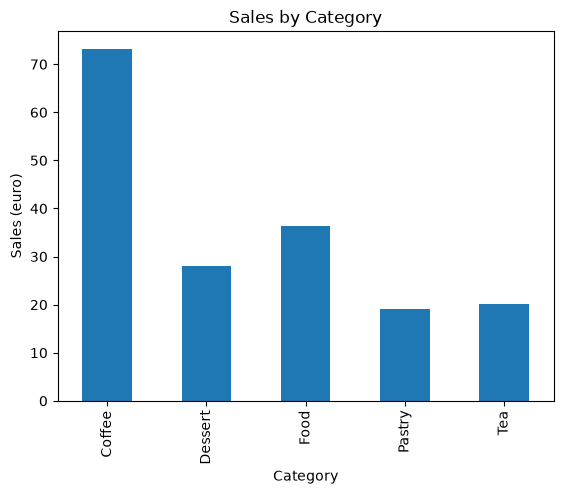

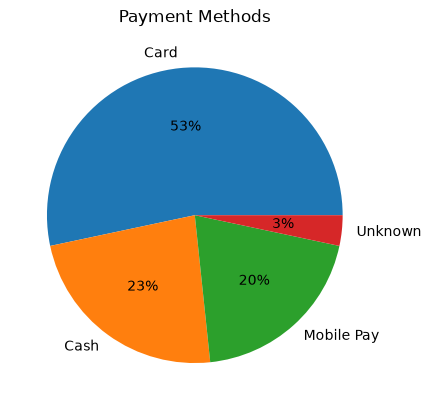

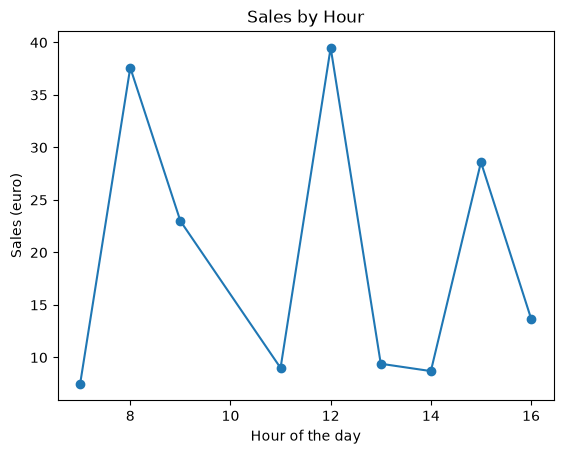

Charts saved.


In [9]:
# STEP 6: CHARTS
print("\n--- STEP 6: CHARTS ---")

# Chart 1: Bar chart - sales by category
sales_by_category.plot(kind="bar")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales (euro)")
plt.show()

# Chart 2: Pie chart - payment methods
payment_counts.plot(kind="pie", autopct="%1.0f%%")
plt.title("Payment Methods")
plt.ylabel("")
plt.show()

# Chart 3: Line chart - sales by hour
sales_by_hour.plot(kind="line", marker="o")
plt.title("Sales by Hour")
plt.xlabel("Hour of the day")
plt.ylabel("Sales (euro)")
plt.show()

print("Charts saved.")

In [10]:
# STEP 7: INSIGHTS
print("\n--- STEP 7: INSIGHTS ---")

print("1. Total sales:", round(total_sales, 2), "euro")
print("2. Average order value:", round(average_order, 2), "euro")
print("3. Best category:", sales_by_category.idxmax())
print("4. Best selling item:", items_sold.idxmax(), "-", items_sold.max(), "sold")
print("5. Busiest hour:", sales_by_hour.idxmax(), ":00")
print("6. Best sales day:", sales_by_day.idxmax())
print("7. Most used payment method:", payment_counts.idxmax())



--- STEP 7: INSIGHTS ---
1. Total sales: 177.0 euro
2. Average order value: 5.9 euro
3. Best category: Coffee
4. Best selling item: Espresso - 5 sold
5. Busiest hour: 12 :00
6. Best sales day: 2026-10-14
7. Most used payment method: Card
